# Model Bayesian stok beras per provinsi (Jan 2024 – Sep 2026)

Notebook ini berisi **hasil model yang sudah dihitung** (output tersimpan, langsung terlihat tanpa menjalankan apa pun)
dan **seluruh kode** untuk membuat ulang hasil itu dari data mentah (bagian 7).

- **Stok** = stok beras total (rumah tangga + penggilingan + pedagang + BULOG + horeka), akhir bulan, juta ton.
- **Angka** = median posterior dan interval kredibel 90% (p05–p95). Skenario dasar: 4 rantai × 1.000 draw, 0 divergensi,
  r-hat maks 1,06.
- **Data**: INATRADE sheet "2024-2026" (semua baris beras, PAW + Non PAW; kg→ton dikoreksi; kode 00372 = BULOG),
  BPS WebAPI (produksi KSA, konsumsi Susenas × penduduk, harga penggilingan), angka publik survei stok, stok BULOG,
  impor (sel `JANGKAR_PUBLIK_CSV` di bagian 7, dengan sumbernya).
- **Model**: neraca bulanan per provinsi (stok = stok lalu + produksi × (1 − susut) + impor + masuk − keluar −
  konsumsi), tiap sumber data punya bias & noise sendiri, stok total provinsi dan stok swasta per pulau ≥ 0.
  Angka BULOG per provinsi dan rincian komponen swasta adalah alokasi model, bukan data.

Menjalankan ulang sel bagian 1–6 hanya butuh pandas + matplotlib (beberapa detik). Bagian 7 butuh pymc dan
file `Non_PAW_dari_nol.xlsm` serta kunci WebAPI BPS.

## 1. Muat hasil yang tertanam

In [1]:
import base64, gzip, io
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Kolom: skenario, tingkat, wilayah, pulau, periode, komponen, median, p05, p95 (juta ton, akhir bulan).
# Skenario "dasar" berisi nasional, pulau dan 38 provinsi; skenario lain hanya nasional.
HASIL_GZ_B64 = """
...
"""
# (uji, periode survei, sumber, amatan, prediksi median, p05, p95, dipakai untuk fit)
VALIDASI = [('validasi (Des 2022 disembunyikan)', '2022-06', 'survei_bps_scbn', 9.71, 9.73, 8.69, 10.916, 'ya'), ('validasi (Des 2022 disembunyikan)', '2022-12', 'survei_bapanas', 4.06, 4.397, 3.435, 5.59, 'tidak (disembunyikan)'), ('validasi (Des 2022 disembunyikan)', '2023-12', 'survei_bapanas', 4.13, 4.228, 3.77, 4.76, 'ya'), ('fit penuh', '2022-06', 'survei_bps_scbn', 9.71, 9.706, 8.709, 10.912, 'ya'), ('fit penuh', '2022-12', 'survei_bapanas', 4.06, 4.099, 3.678, 4.585, 'ya'), ('fit penuh', '2023-12', 'survei_bapanas', 4.13, 4.195, 3.753, 4.7, 'ya')]
# (parameter, mean, batas bawah 90%, batas atas 90%, r_hat) — skenario dasar
PARAMETER = [('susut', 0.0713, 0.0434, 0.0935, 1.011), ('log_1_plus_nu', 0.3413, 0.3072, 0.3749, 1.011), ('dev_tahunan_nu[0]', -0.0195, -0.0674, 0.0292, 1.004), ('dev_tahunan_nu[1]', -0.0114, -0.0405, 0.02, 1.011), ('dev_tahunan_nu[2]', -0.0621, -0.1032, -0.0218, 1.002), ('dev_tahunan_nu[3]', -0.0106, -0.0505, 0.0277, 1.001), ('dev_tahunan_nu[4]', 0.0036, -0.042, 0.048, 1.001), ('sigma_proses', 0.0424, 0.0036, 0.1014, 1.0), ('stok_awal_nasional', 10455273.206, 8570104.3379, 12636716.1279, 1.007), ('tau_theta', 0.0404, 0.0026, 0.1103, 1.015), ('sigma_bulog', 0.2428, 0.1758, 0.3268, 1.065), ('bias_bulog_inatrade', -0.0913, -0.151, -0.0327, 1.001), ('bias_survei[0]', -0.6782, -0.9068, -0.4623, 1.004), ('bias_survei[1]', -0.0649, -0.2682, 0.1325, 1.006), ('mu_a', -8.6272, -9.5571, -7.6708, 1.032), ('tau_a', 1.1205, 0.5766, 1.8944, 1.018), ('sd_inatrade', 0.4392, 0.3641, 0.5174, 1.006), ('c_harga', 0.1005, 0.0396, 0.1613, 1.002), ('beta_harga', -0.1641, -0.3342, 0.0079, 1.002), ('sd_harga', 0.1127, 0.0744, 0.1646, 1.001), ('pangsa_komponen[0]', 0.7962, 0.6699, 0.9019, 1.0), ('pangsa_komponen[1]', 0.0614, 0.01, 0.146, 1.0), ('pangsa_komponen[2]', 0.1045, 0.0322, 0.2075, 1.0), ('pangsa_komponen[3]', 0.0379, 0.0022, 0.106, 1.001)]
NERACA_BAPANAS = {'2024-12': 8.4, '2025-12': 12.529, '2026-09': 17.9}  # pembanding, tanpa susut

R = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(''.join(HASIL_GZ_B64.split())))))
R['pulau'] = R['pulau'].fillna('')
D = R[R.skenario == 'dasar']
KOMP = {'total': 'Total', 'bulog': 'BULOG', 'swasta': 'Swasta (di luar BULOG)', 'rumah_tangga': '  rumah tangga',
        'pedagang': '  pedagang', 'penggilingan': '  penggilingan', 'horeka': '  horeka & industri'}
print(f'{len(R):,} baris; skenario: {sorted(R.skenario.unique())}; bulan {D.periode.min()} s.d. {D.periode.max()}')

11,088 baris; skenario: ['dasar', 'swasta>=0 nasional', 'swasta>=0 per provinsi', 'validasi tanpa SSBAT Des 2022']; bulan 2024-01 s.d. 2026-09


## 2. Nasional

In [2]:
BULAN = '2026-09'   # ganti untuk bulan lain (2024-01 s.d. 2026-09)

n = D[(D.tingkat == 'nasional') & (D.periode == BULAN)].set_index('komponen').loc[list(KOMP)]
tabel = n[['median', 'p05', 'p95']].rename(index=KOMP)
tabel.columns = ['Median (juta ton)', 'p05', 'p95']
print(f'Stok beras nasional akhir {BULAN}')
tabel

Stok beras nasional akhir 2026-09


,Median (juta ton),p05,p95
komponen,,,
Total,14.21,11.31,18.61
BULOG,4.65,4.29,5.04
Swasta (di luar BULOG),9.57,6.74,14.01
rumah tangga,7.59,5.15,11.39
pedagang,0.91,0.30,2.18
penggilingan,0.50,0.09,1.50
horeka & industri,0.26,0.02,1.08


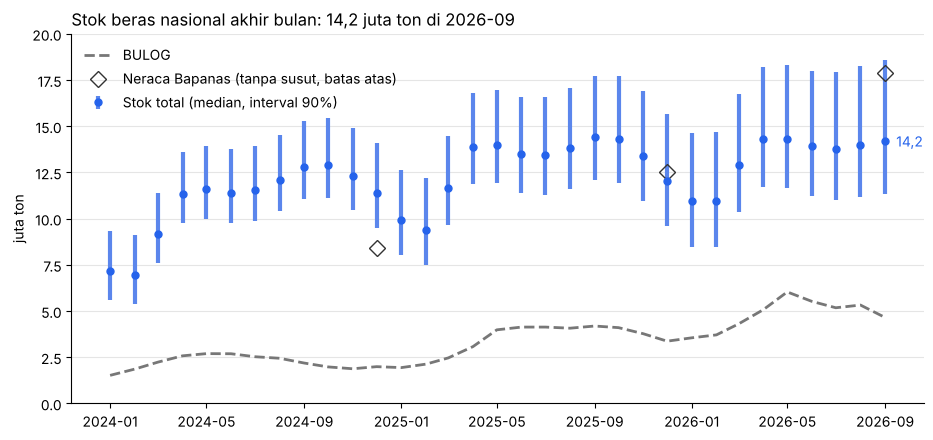

In [3]:
t = D[(D.tingkat == 'nasional') & (D.komponen == 'total')].sort_values('periode')
b = D[(D.tingkat == 'nasional') & (D.komponen == 'bulog')].sort_values('periode')
x = pd.to_datetime(t.periode)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.errorbar(x, t['median'], yerr=[t['median'] - t.p05, t.p95 - t['median']], fmt='o', color='#2563eb',
            ecolor='#5b86ec', elinewidth=3, capsize=0, ms=5, label='Stok total (median, interval 90%)')
ax.plot(pd.to_datetime(b.periode), b['median'], '--', color='#777', lw=2, label='BULOG')
ax.plot(pd.to_datetime(list(NERACA_BAPANAS)), list(NERACA_BAPANAS.values()), 'D', mfc='none', mec='#333', ms=8,
        label='Neraca Bapanas (tanpa susut, batas atas)')
last = t.iloc[-1]
ax.annotate(f"{last['median']:.1f}".replace('.', ','), (x.iloc[-1], last['median']), xytext=(8, -4),
            textcoords='offset points', color='#2563eb')
ax.set_ylim(0, 20); ax.set_ylabel('juta ton')
ax.set_title(f"Stok beras nasional akhir bulan: {last['median']:.1f} juta ton di {last.periode}".replace('.', ','),
             loc='left')
ax.grid(axis='y', color='#e5e5e5'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper left')
plt.show()

In [4]:
# Deret nasional per bulan: total, BULOG, swasta
w = D[D.tingkat == 'nasional'].pivot_table(index='periode', columns='komponen', values=['median', 'p05', 'p95'])
deret = pd.DataFrame({'total': w[('median', 'total')], 'p05': w[('p05', 'total')], 'p95': w[('p95', 'total')],
                      'BULOG': w[('median', 'bulog')], 'swasta': w[('median', 'swasta')]})
deret

,total,p05,p95,BULOG,swasta
periode,,,,,
2024-01,7.18,5.60,9.35,1.52,5.62
2024-02,6.93,5.36,9.11,1.86,5.03
2024-03,9.17,7.59,11.39,2.24,6.81
2024-04,11.35,9.74,13.63,2.58,8.69
2024-05,11.62,10.00,13.93,2.70,8.84
2024-06,11.39,9.75,13.74,2.69,8.67
2024-07,11.55,9.89,13.95,2.53,8.91
2024-08,12.09,10.39,14.54,2.45,9.59
2024-09,12.80,11.05,15.29,2.19,10.57


## 3. Per pulau

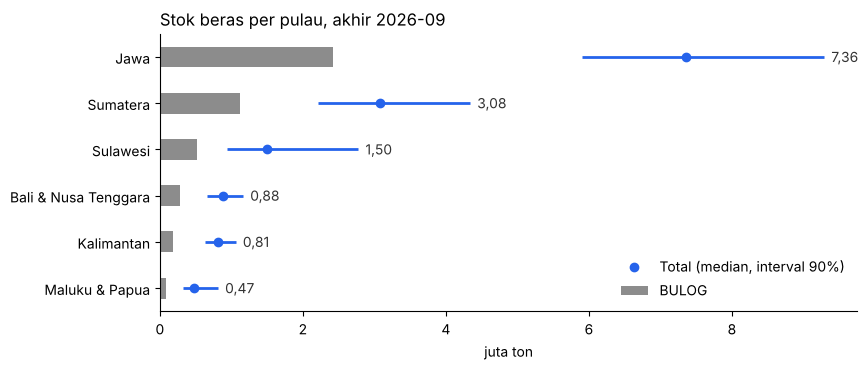

,total,p05,p95,BULOG,swasta
wilayah,,,,,
Jawa,7.36,5.90,9.29,2.42,4.93
Sumatera,3.08,2.21,4.34,1.12,1.97
Sulawesi,1.50,0.94,2.77,0.52,0.99
Bali & Nusa Tenggara,0.88,0.65,1.16,0.28,0.60
Kalimantan,0.81,0.64,1.06,0.19,0.62
Maluku & Papua,0.47,0.32,0.81,0.09,0.39


In [5]:
p = D[(D.tingkat == 'pulau') & (D.periode == BULAN)].pivot_table(index='wilayah', columns='komponen',
                                                                values=['median', 'p05', 'p95'])
pulau = pd.DataFrame({'total': p[('median', 'total')], 'p05': p[('p05', 'total')], 'p95': p[('p95', 'total')],
                      'BULOG': p[('median', 'bulog')], 'swasta': p[('median', 'swasta')]}).sort_values('total')
fig, ax = plt.subplots(figsize=(9, 3.6))
yy = range(len(pulau))
ax.barh(yy, pulau.BULOG, color='#8c8c8c', height=0.45, label='BULOG')
ax.hlines(yy, pulau.p05, pulau.p95, color='#2563eb', lw=2)
ax.plot(pulau.total, yy, 'o', color='#2563eb', label='Total (median, interval 90%)')
for i, (nm, r) in enumerate(pulau.iterrows()):
    ax.text(r.p95 + 0.1, i, f"{r.total:.2f}".replace('.', ','), va='center', color='#333')
ax.set_yticks(list(yy), pulau.index); ax.set_xlabel('juta ton'); ax.set_xlim(0, None)
ax.set_title(f'Stok beras per pulau, akhir {BULAN}', loc='left')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, loc='lower right')
plt.show()
pulau.sort_values('total', ascending=False)

## 4. Per provinsi

In [6]:
q = D[(D.tingkat == 'provinsi') & (D.periode == BULAN)].pivot_table(index=['wilayah', 'pulau'], columns='komponen',
                                                                   values=['median', 'p05', 'p95'])
prov = pd.DataFrame({'total': q[('median', 'total')], 'p05': q[('p05', 'total')], 'p95': q[('p95', 'total')],
                     'BULOG': q[('median', 'bulog')], 'swasta': q[('median', 'swasta')]})
lalu = f"{int(BULAN[:4]) - 1}{BULAN[4:]}"
prev = D[(D.tingkat == 'provinsi') & (D.periode == lalu) & (D.komponen == 'total')].set_index('wilayah')['median']
prov['vs 12 bln (%)'] = [(r.total / prev.get(w, float('nan')) - 1) * 100 for (w, _), r in prov.iterrows()]
prov.sort_values('total', ascending=False)

,,total,p05,p95,BULOG,swasta,vs 12 bln (%)
wilayah,pulau,,,,,,
JAWA BARAT,Jawa,2.26,1.73,2.83,0.77,1.49,0.03
JAWA TIMUR,Jawa,2.14,1.60,3.00,0.72,1.42,6.22
JAWA TENGAH,Jawa,1.90,1.33,2.92,0.63,1.27,-11.60
SULAWESI SELATAN,Sulawesi,0.90,0.35,2.14,0.30,0.58,-0.48
SUMATERA UTARA,Sumatera,0.65,0.33,0.94,0.25,0.39,-12.45
SUMATERA SELATAN,Sumatera,0.62,0.35,1.21,0.22,0.40,30.02
LAMPUNG,Sumatera,0.61,0.39,1.07,0.21,0.39,10.83
BANTEN,Jawa,0.51,0.31,0.77,0.17,0.34,-12.16
NUSA TENGGARA BARAT,Bali & Nusa Tenggara,0.37,0.27,0.50,0.12,0.25,4.80


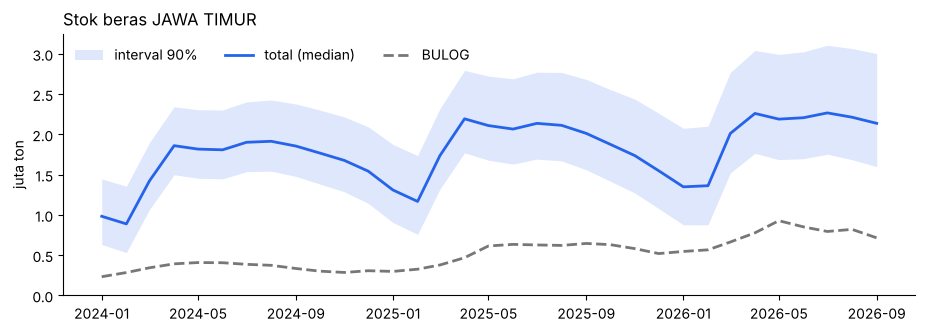

,total,p05,p95,BULOG,swasta
periode,,,,,
2025-10,1.88,1.42,2.56,0.63,1.24
2025-11,1.74,1.27,2.44,0.58,1.16
2025-12,1.55,1.08,2.26,0.52,1.03
2026-01,1.35,0.88,2.08,0.55,0.80
2026-02,1.36,0.88,2.10,0.57,0.79
2026-03,2.01,1.52,2.77,0.66,1.35
2026-04,2.26,1.76,3.04,0.78,1.48
2026-05,2.19,1.69,2.99,0.93,1.26
2026-06,2.21,1.70,3.03,0.85,1.36


In [7]:
WILAYAH = 'JAWA TIMUR'   # nama provinsi (huruf besar) atau pulau, mis. 'Sulawesi'

s = D[D.wilayah == WILAYAH].pivot_table(index='periode', columns='komponen', values=['median', 'p05', 'p95'])
seri = pd.DataFrame({'total': s[('median', 'total')], 'p05': s[('p05', 'total')], 'p95': s[('p95', 'total')],
                     'BULOG': s[('median', 'bulog')], 'swasta': s[('median', 'swasta')]})
fig, ax = plt.subplots(figsize=(11, 3.4))
xx = pd.to_datetime(seri.index)
ax.fill_between(xx, seri.p05, seri.p95, color='#2563eb', alpha=0.15, lw=0, label='interval 90%')
ax.plot(xx, seri.total, color='#2563eb', lw=2, label='total (median)')
ax.plot(xx, seri.BULOG, '--', color='#777', lw=2, label='BULOG')
ax.set_ylim(0, None); ax.set_ylabel('juta ton'); ax.set_title(f'Stok beras {WILAYAH}', loc='left')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, ncol=3, loc='upper left')
plt.show()
seri.tail(12)

## 5. Uji model

- **Validasi**: survei SSBAT Desember 2022 disembunyikan saat fit, lalu ditebak model.
- **Sensitivitas**: tingkat penerapan kendala "stok swasta tidak negatif" adalah pilihan yang paling menentukan level.

In [8]:
val = pd.DataFrame(VALIDASI, columns=['uji', 'periode', 'sumber', 'amatan', 'model_median', 'p05', 'p95', 'dipakai_fit'])
val[val.uji.str.startswith('validasi')]

,uji,periode,sumber,amatan,model_median,p05,p95,dipakai_fit
0,validasi (Des 2022 disembunyikan),2022-06,survei_bps_scbn,9.71,9.73,8.69,10.92,ya
1,validasi (Des 2022 disembunyikan),2022-12,survei_bapanas,4.06,4.40,3.44,5.59,tidak (disembunyikan)
2,validasi (Des 2022 disembunyikan),2023-12,survei_bapanas,4.13,4.23,3.77,4.76,ya


In [9]:
sens = R[(R.tingkat == 'nasional') & (R.komponen == 'total') & (R.periode == '2026-09')
         & (R.skenario != 'validasi tanpa SSBAT Des 2022')]
sens = sens.set_index('skenario')[['median', 'p05', 'p95']]
sens.index = sens.index.map({'dasar': 'swasta ≥ 0 per pulau (dasar)', 'swasta>=0 nasional': 'swasta ≥ 0 nasional saja',
                             'swasta>=0 per provinsi': 'swasta ≥ 0 per provinsi'})
print('Stok nasional akhir Sep 2026 (juta ton)')
sens

Stok nasional akhir Sep 2026 (juta ton)


,median,p05,p95
skenario,,,
swasta ≥ 0 per pulau (dasar),14.21,11.31,18.61
swasta ≥ 0 per provinsi,16.77,13.98,21.27
swasta ≥ 0 nasional saja,14.16,11.38,19.12


In [10]:
par = pd.DataFrame(PARAMETER, columns=['parameter', 'mean', 'p05', 'p95', 'r_hat']).set_index('parameter')
par.loc[['susut', 'log_1_plus_nu', 'bias_survei[0]', 'bias_survei[1]', 'beta_harga', 'pangsa_komponen[0]',
         'pangsa_komponen[1]', 'pangsa_komponen[2]', 'pangsa_komponen[3]']].style.format('{:.3f}')

,mean,p05,p95,r_hat
parameter,,,,
susut,0.071,0.043,0.093,1.011
log_1_plus_nu,0.341,0.307,0.375,1.011
bias_survei[0],-0.678,-0.907,-0.462,1.004
bias_survei[1],-0.065,-0.268,0.133,1.006
beta_harga,-0.164,-0.334,0.008,1.002
pangsa_komponen[0],0.796,0.670,0.902,1.000
pangsa_komponen[1],0.061,0.010,0.146,1.000
pangsa_komponen[2],0.104,0.032,0.207,1.000
pangsa_komponen[3],0.038,0.002,0.106,1.001


## 6. Ekspor (opsional)

In [11]:
EKSPOR = False   # ubah ke True untuk menulis file
if EKSPOR:
    R.to_csv('stok_beras_posterior.csv', index=False)
    with pd.ExcelWriter('stok_beras_posterior.xlsx') as W:   # butuh openpyxl
        for tk in ['nasional', 'pulau', 'provinsi']:
            x = D[D.tingkat == tk].pivot_table(index=['pulau', 'wilayah', 'periode'] if tk == 'provinsi' else
                                               ['wilayah', 'periode'], columns='komponen',
                                               values=['median', 'p05', 'p95'])
            x.columns = [f'{k} {s}' for s, k in x.columns]
            (x * 1000).round(1).to_excel(W, sheet_name=tk)   # ribu ton
        sens.to_excel(W, sheet_name='sensitivitas'); val.to_excel(W, sheet_name='validasi', index=False)
    print('ditulis stok_beras_posterior.csv dan .xlsx')

## 7. Kode untuk menjalankan ulang model dari data mentah

Sel-sel di bawah hanya **mendefinisikan** fungsi; model baru jalan bila `JALANKAN_ULANG = True` di sel terakhir.
Kebutuhan: `pip install pymc nutpie pandas numpy openpyxl`, file `Non_PAW_dari_nol.xlsm`, dan env var `BPS_API_KEY`
(kunci WebAPI BPS). Satu run model ±10 menit (4 inti CPU).

In [12]:
import argparse, json, math, os, re, sys, time, urllib.request
import numpy as np
try:
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.utils import get_column_letter
except ImportError:
    pass

JANGKAR_PUBLIK_CSV = """jenis,periode,nilai_juta_ton,sumber,catatan,url
survei_bps_scbn,2022-06,9.71,BPS Survei Cadangan Beras Nasional 2022,"RT 6,6; BULOG 1,11; pedagang 1,04; penggilingan 0,69; horeka 0,28",https://www.fortuneidn.com/news/eko-wahyudi/stok-beras-nasional-mencapai-9-71-juta-ton-ini-persebarannya
survei_bapanas,2022-12,4.06,Survei Stok Beras Akhir Tahun (SSBAT) Bapanas-BPS,posisi 31 Des 2022,https://insight.kontan.co.id/news/pergeseran-stok-beras-di-masyarakat
survei_bapanas,2023-12,4.13,Survei Stok Beras Akhir Tahun (SSBAT) Bapanas-BPS,"posisi 31 Des 2023; RT 66,34%, BULOG 19,6%, pedagang 6,74%; 477 kab/kota",https://insight.kontan.co.id/news/pergeseran-stok-beras-di-masyarakat
bulog_publik,2023-03,0.245,BULOG,per 31 Maret 2023,https://ekonomi.bisnis.com/read/20230403/12/1643196/menipis-stok-beras-bulog-245233-ton-per-31-maret-2023
bulog_publik,2023-12,1.26,BULOG,per 20 Desember 2023,https://ekonomi.bisnis.com/read/20231221/12/1726067/bulog-pastikan-stok-beras-aman-hingga-juni-2024
bulog_publik,2024-12,2.0,BULOG / Menko Pangan,"2,07 per 10 Des; perkiraan akhir tahun 1,95",https://jabar.antaranews.com/berita/561697/menko-pangan-sebut-stok-beras-nasional-capai-tertinggi-dalam-5-tahun
bulog_publik,2025-01,1.94,BULOG,per 4 Februari 2025,https://ekonomi.bisnis.com/read/20250204/12/1836714/bulog-stok-beras-ri-capai-194-juta-ton-4-februari-2025
bulog_publik,2025-05,4.0,BULOG,awal Juni 2025,https://www.bulog.co.id/2025/06/03/stok-beras-tembus-4-juta-ton-tertinggi-sejak-bulog-berdiri/
bulog_publik,2025-11,3.8,BULOG,per 20 November 2025,https://pasardana.id/news/2025/11/21/antisipasi-over-stock-bulog-buka-peluang-buat-ekspor-beras/
bulog_publik,2025-12,3.53,Bapanas,"perkiraan akhir 2025 (3,5 per 22 Des)",https://periskop.id/ekonomi/20251222/bapanas-stok-beras-aman-hingga-ramadan
bulog_publik,2026-03,4.3,Bapanas,Maret 2026,https://www.antaranews.com/berita/5500930/bapanas-stok-beras-43-juta-ton-ketahanan-pangan-ri-hadapi-geopolitik
bulog_publik,2026-06,5.4,BULOG,"rekor Juni 2026 (5,18 per 2 Juli)",https://nasional.kontan.co.id/news/bulog-serap-32-juta-ton-beras-stok-tembus-rekor-54-juta-ton
bulog_publik,2026-09,4.6,BULOG / Bapanas,"4,5-4,8 akhir Sep-awal Okt 2026",https://www.rctiplus.com/news/detail/terkini/5475938/bulog-pastikan-stok-beras-4-6-juta-ton-siap-jaga-pasokan-hingga-akhir-tahun
impor,2022-H2,0.3,BPS (perkiraan),"impor 2022 0,43 juta ton, sebagian besar akhir tahun; dibagi rata Jul-Des",
impor,2023,3.06,BPS,dibagi rata per bulan,
impor,2024,4.52,BPS,dibagi rata per bulan,https://www.cnbcindonesia.com/news/20250116085359-4-603570/impor-beras-ri-sepanjang-2024-tembus-452-juta-ton-ini-pemasoknya
impor,2025,0.0,BPS / Bapanas,tidak ada impor beras konsumsi,
impor,2026,0.0,BPS / Bapanas,tidak ada impor beras konsumsi,
konsumsi_bapanas,2026,2.591,Bapanas neraca 2026,"juta ton per bulan, termasuk non rumah tangga",https://www.antaranews.com/berita/5331646/bapanas-ri-swasembada-beras-stok-awal-2026-capai-12529-juta-ton?page=all
neraca_bapanas,2024-12,8.4,Bapanas,carry over 2024 (pembanding; tidak dipakai untuk fit),https://ekonomi.republika.co.id/berita/t77bui423/stok-beras-nasional-aman-bapanas-proyeksikan-125-juta-ton-di-akhir-2025
neraca_bapanas,2025-12,12.529,Bapanas,stok awal 2026 (pembanding; tidak dipakai untuk fit),https://www.antaranews.com/berita/5331646/bapanas-ri-swasembada-beras-stok-awal-2026-capai-12529-juta-ton?page=all
neraca_bapanas,2026-09,17.9,hitungan neraca,"12,53 + produksi Jan-Sep 28,71 - konsumsi 23,32 (pembanding)",
"""

### 7a. Pembacaan dan panel INATRADE
Satu laporan = perusahaan × bulan × sub komoditi; laporan ≥100× pola perusahaannya dianggap kg → ÷1000; kode 00372 = BULOG.

In [13]:
BULAN = {'JANUARI': 1, 'FEBRUARI': 2, 'MARET': 3, 'APRIL': 4, 'MEI': 5, 'JUNI': 6, 'JULI': 7,
         'AGUSTUS': 8, 'SEPTEMBER': 9, 'OKTOBER': 10, 'NOVEMBER': 11, 'DESEMBER': 12}


def kosong(v):
    return v is None or (isinstance(v, float) and math.isnan(v)) or str(v).strip() == ''


def U(v):
    return '' if kosong(v) else re.sub(' +', ' ', str(v).strip().upper())


def angka(v):
    """Angka dari sel; format Indonesia 1.234,5 dikenali. None bila kosong."""
    if kosong(v):
        return None
    if isinstance(v, (int, float)):
        return float(v)
    t = ''.join(c for c in str(v) if c.isdigit() or c in ',.-')
    if not any(c.isdigit() for c in t):
        return None
    if re.fullmatch(r'-?\d{1,3}(\.\d{3})+(,\d*)?', t):
        t = t.replace('.', '').replace(',', '.')
    else:
        t = t.replace(',', '')
    try:
        return float(re.match(r'-?\d*\.?\d*', t).group(0))
    except ValueError:
        return 0.0


def a0(v):
    x = angka(v)
    return 0.0 if x is None else x


def normprov(v):
    s = U(v)
    for p in ('PROVINSI ', 'PROV. '):
        if s.startswith(p):
            s = s[len(p):].strip()
    return s


def periode_inatrade(bulan, tahun):
    """'2026-09' dari ('SEPTEMBER', 2026); None bila tak terbaca."""
    b = BULAN.get(U(bulan))
    t = angka(tahun)
    if not b or t is None:
        return None
    return f'{int(t)}-{b:02d}'


KODE_BULOG = '00372'


AMBANG_KG = 100


Q = ['Pengadaan', 'Penyaluran', 'Stok Awal', 'Stok Akhir']


def inatrade_baca(path, baris='semua'):
    """baris: 'semua', 'nonpaw' (Provinsi Perusahaan = Provinsi Penyaluran) atau 'paw' (berbeda)."""
    S = pd.read_excel(path, sheet_name='2024-2026', dtype=object)
    B = S[S['Jenis Komoditi'].map(U) == 'BERAS'].copy().reset_index(drop=True)
    B['kode'] = B['Nama Perusahaan'].astype(str).str.strip().str.zfill(5)
    B['periode'] = [periode_inatrade(b, t) for b, t in zip(B['Bulan'], B['Tahun'])]
    B['sub'] = B['Sub Komoditi'].astype(str).str.strip()
    B['prov'] = B['Provinsi Perusahaan'].map(normprov)
    B['prov_tujuan'] = B['Provinsi Penyaluran'].map(normprov)
    B['prov_asal'] = B['Asal Pengadaan'].map(normprov)
    for c in Q + ['Rincian Pengadaan', 'Rincian Penyaluran', 'Harga Jual']:
        B[c] = B[c].map(a0)
    B = B.dropna(subset=['periode'])
    if baris == 'nonpaw':
        B = B[B['prov_tujuan'] == B['prov']]
    elif baris == 'paw':
        B = B[(B['prov_tujuan'] != '') & (B['prov_tujuan'] != B['prov'])]
    return B.reset_index(drop=True)


def inatrade_laporan(B):
    L = B.groupby(['kode', 'periode', 'sub'], as_index=False).agg(
        prov=('prov', 'first'), peng=('Pengadaan', 'max'), peny=('Penyaluran', 'max'),
        sa=('Stok Awal', 'max'), sk=('Stok Akhir', 'max'), baris=('periode', 'size'))
    base = {}
    for k, g in L.groupby(['kode', 'sub']):
        v = g[['peny', 'sa', 'sk', 'peng']].replace(0, np.nan).stack()
        base[k] = v.median() if len(v) else np.nan
    L['basis'] = [base[(a, b)] for a, b in zip(L['kode'], L['sub'])]
    besar = L[['peny', 'sa', 'sk', 'peng']].max(axis=1) / L['basis']
    L['faktor'] = np.where((L['basis'] > 0) & (besar >= AMBANG_KG), 1 / 1000, 1.0)
    for c in ['peng', 'peny', 'sa', 'sk']:
        L[c] = L[c] * L['faktor']
    L['bulog'] = L['kode'] == KODE_BULOG
    L['cover_bln'] = np.where(L['peny'] > 0, L['sk'] / L['peny'], np.nan)
    return L


def inatrade_panel(L):
    T = L[~L['bulog']]
    P = T.groupby(['prov', 'periode']).agg(
        perusahaan=('kode', 'nunique'), laporan=('kode', 'size'),
        penyaluran_ton=('peny', 'sum'), stok_akhir_ton=('sk', 'sum'),
        cover_median_bln=('cover_bln', 'median')).reset_index()
    nas = T.groupby('periode')['cover_bln'].median().rename('cover_nasional_bln')
    P = P.join(nas, on='periode')
    P['indeks_cover'] = P['cover_median_bln'] / P['cover_nasional_bln']
    return P


def inatrade_arus(B, L):
    fx = dict(zip(zip(L['kode'], L['periode'], L['sub']), L['faktor']))
    B = B[B['kode'] != KODE_BULOG].copy()
    f = [fx.get(k, 1.0) for k in zip(B['kode'], B['periode'], B['sub'])]
    B['vol_jual'] = B['Rincian Penyaluran'] * f
    B['vol_beli'] = B['Rincian Pengadaan'] * f
    jual = B[(B['prov_tujuan'] != '') & (B['vol_jual'] > 0)].groupby(
        ['periode', 'prov', 'prov_tujuan'], as_index=False)['vol_jual'].sum()
    jual.columns = ['periode', 'asal', 'tujuan', 'ton']
    beli = B[(B['prov_asal'] != '') & (B['vol_beli'] > 0)].groupby(
        ['periode', 'prov_asal', 'prov'], as_index=False)['vol_beli'].sum()
    beli.columns = ['periode', 'asal', 'tujuan', 'ton']
    return jual, beli


def jalankan_inatrade(path, out, baris='semua'):
    os.makedirs(out, exist_ok=True)
    B = inatrade_baca(path, baris)
    L = inatrade_laporan(B)
    P = inatrade_panel(L)
    jual, beli = inatrade_arus(B, L)
    L.to_csv(os.path.join(out, 'laporan.csv'), index=False)
    P.to_csv(os.path.join(out, 'panel_provinsi.csv'), index=False)
    jual.to_csv(os.path.join(out, 'arus_penyaluran.csv'), index=False)
    beli.to_csv(os.path.join(out, 'arus_pengadaan.csv'), index=False)
    print(f'{len(B)} baris beras, {len(L)} laporan ({int((L.faktor < 1).sum())} dikoreksi kg->ton)')
    print(f'{P.prov.nunique()} provinsi pelapor, {len(P)} sel provinsi-bulan')
    print(f'arus penyaluran: {len(jual)} baris, antar provinsi {int((jual.asal != jual.tujuan).sum())}')
    print(f'arus pengadaan: {len(beli)} baris, antar provinsi {int((beli.asal != beli.tujuan).sum())}')

### 7b. Data BPS (WebAPI)

In [14]:
BPS_BASE = 'https://webapi.bps.go.id/v1/api/list/model/data/lang/ind/domain/0000/var/{var}/th/{th}/key/{key}/'


BPS_TH = {y: y - 1900 for y in range(2018, 2027)}


def bps_ambil(var, tahun, cache):
    th = ';'.join(str(BPS_TH[y]) for y in tahun)
    f = os.path.join(cache, f'{var}_{th.replace(";", "-")}.json')
    if not os.path.exists(f):
        url = BPS_BASE.format(var=var, th=th, key=os.environ['BPS_API_KEY'])
        for i in range(4):
            try:
                with urllib.request.urlopen(url, timeout=120) as r:
                    data = r.read()
                break
            except OSError:
                time.sleep(2 ** (i + 1))
        else:
            raise RuntimeError(f'gagal ambil var {var}')
        with open(f, 'wb') as h:
            h.write(data)
    with open(f) as h:
        return json.load(h)


def bps_urai(d):
    """datacontent BPS -> DataFrame (vervar, turvar, tahun, turtahun, nilai).

    Kunci datacontent = vervar + var + turvar + th_id + turtahun (tanpa pemisah)."""
    var = str(d['var'][0]['val'])
    vv = {str(x['val']): x['label'] for x in d['vervar']}
    tv = [str(x['val']) for x in d['turvar']]
    th = {str(x['val']): x['label'] for x in d['tahun']}
    tt = [str(x['val']) for x in d['turtahun']]
    rows = []
    for k, v in d['datacontent'].items():
        for a in vv:
            if not k.startswith(a + var):
                continue
            rest = k[len(a) + len(var):]
            for b in tv:
                if not rest.startswith(b):
                    continue
                r2 = rest[len(b):]
                for c in th:
                    if r2.startswith(c) and r2[len(c):] in tt:
                        rows.append((a, vv[a], b, int(th[c]), int(r2[len(c):]), v))
    return pd.DataFrame(rows, columns=['kode', 'wilayah', 'turvar', 'tahun', 'turtahun', 'nilai'])


def bps_nama_prov(s):
    s = s.replace('<b>', '').replace('</b>', '').strip().upper()
    return {'KEP. BANGKA BELITUNG': 'KEPULAUAN BANGKA BELITUNG', 'KEP. RIAU': 'KEPULAUAN RIAU',
            'DI YOGYAKARTA': 'DAERAH ISTIMEWA YOGYAKARTA', 'D I YOGYAKARTA': 'DAERAH ISTIMEWA YOGYAKARTA'}.get(s, s)


def jalankan_bps(cache, out):
    os.makedirs(cache, exist_ok=True)
    os.makedirs(out, exist_ok=True)

    # produksi bulanan KSA 2025-2026
    m = bps_urai(bps_ambil(2506, [2025, 2026], cache))
    m = m[(m.turtahun <= 12) & (m.kode != '9999')]
    m['prov'] = m.wilayah.map(bps_nama_prov)
    m['periode'] = m.tahun.astype(str) + '-' + m.turtahun.map('{:02d}'.format)
    m = m[m.prov != 'INDONESIA'][['prov', 'periode', 'nilai']].rename(columns={'nilai': 'padi_gkg_ton'})
    m['potensi'] = m.periode.isin(['2026-09', '2026-10', '2026-11', '2026-12'])
    m.sort_values(['prov', 'periode']).to_csv(os.path.join(out, 'produksi_bulanan_ksa.csv'), index=False)

    # produksi tahunan 2022-2024 (turvar 1193 = produksi ton)
    a = bps_urai(bps_ambil(1498, [2022, 2023, 2024], cache))
    a = a[(a.turvar == '1193')]
    a['prov'] = a.wilayah.map(bps_nama_prov)
    a = a[a.prov != 'INDONESIA'][['prov', 'tahun', 'nilai']].rename(columns={'nilai': 'padi_gkg_ton'})
    a.sort_values(['prov', 'tahun']).to_csv(os.path.join(out, 'produksi_tahunan.csv'), index=False)

    # konsumsi beras per kapita (kab/kota) dibobot penduduk kab/kota -> provinsi
    rows = []
    for y in [2022, 2023, 2024, 2025]:
        k = bps_urai(bps_ambil(2094, [y], cache))
        k = k[k.turvar == '1735'][['kode', 'nilai']].rename(columns={'nilai': 'kg_minggu'})
        p = bps_urai(bps_ambil(2790, [y], cache))
        p = p[p.turvar == '23'][['kode', 'wilayah', 'nilai']].rename(columns={'nilai': 'jiwa'})
        prov = p[p.kode.str.endswith('00')].copy()
        prov['prov'] = prov.wilayah.map(bps_nama_prov)
        kab = p[~p.kode.str.endswith('00')].merge(k, on='kode', how='left')
        kab['pkode'] = kab.kode.str[:2] + '00'
        for pk, g in kab.groupby('pkode'):
            g2 = g.dropna(subset=['kg_minggu'])
            nm = prov.loc[prov.kode == pk, 'prov']
            if not len(nm) or not len(g2):
                continue
            jiwa = float(prov.loc[prov.kode == pk, 'jiwa'].iloc[0])
            kgm = (g2.kg_minggu * g2.jiwa).sum() / g2.jiwa.sum()
            rows.append((nm.iloc[0], y, jiwa, kgm, len(g2), len(g)))
    K = pd.DataFrame(rows, columns=['prov', 'tahun', 'penduduk', 'beras_kg_kapita_minggu', 'kab_ada', 'kab_total'])
    K['konsumsi_rt_ton_bulan'] = K.penduduk * K.beras_kg_kapita_minggu * 52 / 12 / 1000
    K.sort_values(['prov', 'tahun']).to_csv(os.path.join(out, 'konsumsi_provinsi.csv'), index=False)

    # harga beras penggilingan bulanan nasional
    hs = []
    for var, th in [(500, [2022, 2023]), (2277, [2024, 2025])]:
        d = bps_ambil(var, th, cache)
        x = bps_urai(d)
        x['kualitas'] = x.wilayah.str.strip().str.upper()
        hs.append(x)
    h = pd.concat(hs)
    h = h[(h.turtahun <= 12) & h.kualitas.isin(['PREMIUM', 'MEDIUM'])]
    h['periode'] = h.tahun.astype(str) + '-' + h.turtahun.map('{:02d}'.format)
    h[['periode', 'kualitas', 'nilai']].rename(columns={'nilai': 'rp_kg'}).sort_values(
        ['kualitas', 'periode']).to_csv(os.path.join(out, 'harga_penggilingan.csv'), index=False)

    print(f'produksi bulanan: {m.prov.nunique()} prov, {m.periode.nunique()} bulan;'
          f' tahunan {a.prov.nunique()} prov x {a.tahun.nunique()} th')
    print(f'konsumsi: {len(K)} baris; nasional RT 2025 = '
          f'{K[K.tahun == 2025].konsumsi_rt_ton_bulan.sum() / 1e6:.3f} juta ton/bulan')
    print(f'harga: {h.periode.nunique()} bulan, kualitas {sorted(h.kualitas.unique())}')

### 7c. Model (PyMC)

In [15]:
KONV = 0.5762


AWAL, AKHIR = '2022-07', '2026-09'


PULAU = {
    'Sumatera': ['ACEH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'RIAU', 'JAMBI', 'SUMATERA SELATAN', 'BENGKULU',
                 'LAMPUNG', 'KEPULAUAN BANGKA BELITUNG', 'KEPULAUAN RIAU'],
    'Jawa': ['DKI JAKARTA', 'JAWA BARAT', 'JAWA TENGAH', 'DAERAH ISTIMEWA YOGYAKARTA', 'JAWA TIMUR', 'BANTEN'],
    'Bali & Nusa Tenggara': ['BALI', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR'],
    'Kalimantan': ['KALIMANTAN BARAT', 'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR',
                   'KALIMANTAN UTARA'],
    'Sulawesi': ['SULAWESI UTARA', 'SULAWESI TENGAH', 'SULAWESI SELATAN', 'SULAWESI TENGGARA', 'GORONTALO',
                 'SULAWESI BARAT'],
    'Maluku & Papua': ['MALUKU', 'MALUKU UTARA', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA', 'PAPUA SELATAN',
                       'PAPUA TENGAH', 'PAPUA PEGUNUNGAN'],
}


PROV = [p for v in PULAU.values() for p in v]


PULAU_DARI = {p: k for k, v in PULAU.items() for p in v}


KOMP_SWASTA = ['rumah_tangga', 'penggilingan', 'pedagang', 'horeka']


PANGSA_SURVEI = [0.796, 0.062, 0.104, 0.038]


def siapkan(data, holdout=None, tanpa=()):
    bulan = pd.period_range(AWAL, AKHIR, freq='M')
    per = [str(b) for b in bulan]
    T, N = len(per), len(PROV)
    ip = {p: i for i, p in enumerate(PROV)}
    it = {b: i + 1 for i, b in enumerate(per)}  # indeks keadaan; 0 = akhir Jun 2022

    # produksi
    ksa = pd.read_csv(os.path.join(data, 'produksi_bulanan_ksa.csv'))
    th = pd.read_csv(os.path.join(data, 'produksi_tahunan.csv'))
    k25 = ksa[ksa.periode.str.startswith('2025')].copy()
    k25['m'] = k25.periode.str[5:].astype(int)
    pola = k25.pivot(index='prov', columns='m', values='padi_gkg_ton')
    pola = pola.div(pola.sum(axis=1), axis=0)
    kmap = {(r.prov, r.periode): r.padi_gkg_ton for r in ksa.itertuples()}
    tmap = {(r.prov, r.tahun): r.padi_gkg_ton for r in th.itertuples() if not np.isnan(r.padi_gkg_ton)}
    # 2022: provinsi pemekaran Papua masih tergabung di provinsi induk -> bagi menurut pangsa 2023
    for induk, anak in [('PAPUA', ['PAPUA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']),
                        ('PAPUA BARAT', ['PAPUA BARAT', 'PAPUA BARAT DAYA'])]:
        tot22, tot23 = tmap[(induk, 2022)], sum(tmap[(a, 2023)] for a in anak)
        for a in anak:
            tmap[(a, 2022)] = tot22 * tmap[(a, 2023)] / tot23
    prod = np.zeros((N, T))
    sumber_prod = np.empty((N, T), dtype=object)
    for p in PROV:
        for b in per:
            y, m = int(b[:4]), int(b[5:])
            if (p, b) in kmap:
                v, src = kmap[(p, b)], 'KSA bulanan' + (' (potensi)' if b >= '2026-09' else '')
            else:
                v, src = tmap[(p, y)] * pola.loc[p, m], 'KSA tahunan x pola 2025'
            prod[ip[p], it[b] - 1] = v * KONV
            sumber_prod[ip[p], it[b] - 1] = src

    # konsumsi rumah tangga (Susenas x penduduk); 2026 = 2025 x 1,01
    K = pd.read_csv(os.path.join(data, 'konsumsi_provinsi.csv'))
    kc = {(r.prov, r.tahun): r.konsumsi_rt_ton_bulan for r in K.itertuples()}
    cons = np.array([[kc[(p, min(int(b[:4]), 2025))] * (1.01 if b >= '2026' else 1.0) for b in per]
                     for p in PROV])
    cbar = cons.mean(axis=1)
    wcons = cbar / cbar.sum()

    # jangkar publik
    J = pd.read_csv(io.StringIO(JANGKAR_PUBLIK_CSV))
    imp = np.zeros(T)
    for r in J[J.jenis == 'impor'].itertuples():
        if r.periode == '2022-H2':
            idx = [it[b] - 1 for b in per if '2022-07' <= b <= '2022-12']
        else:
            idx = [it[b] - 1 for b in per if b.startswith(r.periode)]
        imp[idx] = r.nilai_juta_ton * 1e6 / 12 if r.periode != '2022-H2' else r.nilai_juta_ton * 1e6 / 6
    kons_bapanas = float(J[J.jenis == 'konsumsi_bapanas'].nilai_juta_ton.iloc[0]) * 1e6

    surv = []  # (t, nilai ton, sumber, dipakai)
    t0 = {'2022-06': 0}
    for r in J[J.jenis.str.startswith('survei')].itertuples():
        t = t0.get(r.periode, it.get(r.periode))
        surv.append((t, r.nilai_juta_ton * 1e6, r.jenis, r.periode != holdout, r.periode))
    bulog = []
    for r in J[J.jenis == 'bulog_publik'].itertuples():
        if r.periode in it:
            bulog.append((it[r.periode], r.nilai_juta_ton * 1e6, 0))
    L = pd.read_csv(os.path.join(data, 'laporan.csv'), dtype={'kode': str})
    Lb = L[L.bulog].groupby('periode')['sk'].sum()
    for b, v in Lb.items() if 'bulog_inatrade' not in tanpa else []:
        # Sep 2026: stok akhir turun ke 2,2 juta ton karena "penyaluran" 3,1 juta ton yang bukan transaksi
        # pasar (lihat catatan sesi) -> tidak dipakai.
        if b in it and b != '2026-09' and v > 0:
            bulog.append((it[b], float(v), 1))

    # INATRADE pedagang, diagregasi per pulau (komposisi pelapor per provinsi terlalu berubah-ubah)
    P = pd.read_csv(os.path.join(data, 'panel_provinsi.csv'))
    P = P[(P.stok_akhir_ton > 0) & P.prov.isin(PROV) & P.periode.isin(per)].copy()
    P['pulau'] = P.prov.map(PULAU_DARI)
    G = P.groupby(['pulau', 'periode'], as_index=False)[['stok_akhir_ton', 'perusahaan']].sum()
    G = G[G.perusahaan >= 2]
    pl = list(PULAU)
    inat = (np.array([pl.index(g) for g in G.pulau]), np.array([it[b] for b in G.periode]),
            np.log(G.stok_akhir_ton / G.perusahaan).values)

    # harga penggilingan medium: perubahan log 12 bulan, tiap 3 bulan (mengurangi autokorelasi)
    H = pd.read_csv(os.path.join(data, 'harga_penggilingan.csv'))
    H = H[H.kualitas == 'MEDIUM'].set_index('periode').rp_kg
    harga = []
    for b in per:
        b12 = str(pd.Period(b) - 12)
        if b in H.index and b12 in H.index and b12 in it and int(b[5:]) % 3 == 0:
            harga.append((it[b], it[b12], np.log(H[b] / H[b12])))
    harga = np.array(harga)

    # arus antar provinsi -> matriks pangsa asal O[q, p]
    pbar = prod.mean(axis=1)
    surplus0 = pbar * 0.95 - cbar * (kons_bapanas / cons[:, -1].sum())
    sp = np.clip(surplus0, 0, None)
    pul = np.array([PULAU_DARI[p] for p in PROV])
    grav = sp[None, :] * np.where(pul[:, None] == pul[None, :], 3.0, 1.0)
    np.fill_diagonal(grav, 0)
    grav = grav / grav.sum(axis=1, keepdims=True)
    inat_o = np.zeros((N, N))
    for f in ['arus_penyaluran.csv', 'arus_pengadaan.csv']:
        A = pd.read_csv(os.path.join(data, f))
        A = A[A.asal.isin(PROV) & A.tujuan.isin(PROV) & (A.asal != A.tujuan)]
        for r in A.itertuples():
            if sp[ip[r.asal]] > 0:  # hanya provinsi surplus yang bisa jadi asal bersih
                inat_o[ip[r.tujuan], ip[r.asal]] += r.ton
    tot = inat_o.sum(axis=1, keepdims=True)
    w = np.where(tot > 0, tot / (tot + 12 * 0.05 * cbar[:, None]), 0.0)  # bobot data ~ tonase relatif
    w = np.minimum(w, 0.7)
    O = (1 - w) * grav + w * np.divide(inat_o, tot, out=np.zeros_like(inat_o), where=tot > 0)
    de = np.clip(-surplus0, 0, None)
    Mq = de[:, None] * O
    target = sp / sp.sum() * de.sum()
    for _ in range(200):  # RAS: baris = defisit tujuan, kolom = kiriman sebanding surplus asal
        cs = Mq.sum(axis=0)
        Mq = Mq * np.divide(target, cs, out=np.ones_like(cs), where=cs > 0)[None, :]
        rs = Mq.sum(axis=1)
        Mq = Mq * np.divide(de, rs, out=np.zeros_like(rs), where=rs > 0)[:, None]
    O = np.divide(Mq, de[:, None], out=np.zeros_like(Mq), where=de[:, None] > 0)

    musim_prov = prod / prod.mean(axis=1, keepdims=True)
    tahun = sorted({b[:4] for b in per})
    idx_tahun = np.array([tahun.index(b[:4]) for b in per])
    return dict(musim_prov=musim_prov, tahun=tahun, idx_tahun=idx_tahun, per=per, T=T, N=N, prod=prod, sumber_prod=sumber_prod, cons=cons, cbar=cbar, wcons=wcons,
                imp=imp, kons_bapanas=kons_bapanas, surv=surv, bulog=bulog, inat=inat, harga=harga, O=O,
                w_inat=w[:, 0], pbar=pbar)


def grup(tingkat):
    if tingkat == 'provinsi':
        return np.eye(len(PROV))
    if tingkat == 'nasional':
        return np.ones((1, len(PROV)))
    return np.array([[1.0 if PULAU_DARI[p] == k else 0.0 for p in PROV] for k in PULAU])


def bangun(D):
    import pymc as pm
    import pytensor.tensor as pt

    N, T = D['N'], D['T']
    cons, prod, cbar = D['cons'], D['prod'], D['cbar']
    nu_mu = np.log(D['kons_bapanas'] / cons[:, -1].sum())
    with pm.Model() as m:
        s = pm.Deterministic('susut', 0.025 + 0.075 * pm.Beta('susut_b', 2, 2))
        lognu = pm.Normal('log_1_plus_nu', nu_mu, 0.1)
        # simpangan tahunan konsumsi non-RT/kehilangan (2022..2026), prior ketat
        dnu = pm.Normal('dev_tahunan_nu', 0, D.get('sd_tahunan', 0.03), shape=len(D['tahun']))
        fnu_t = pt.exp(lognu + dnu[D['idx_tahun']])  # per bulan
        fnu = pt.exp(lognu)
        sigma = pm.HalfNormal('sigma_proses', 0.05)
        X0n = pm.LogNormal('stok_awal_nasional', np.log(8e6), 0.5)
        a0 = 0.5 * cbar / cbar.sum() + 0.5 * D['pbar'] / D['pbar'].sum()
        sh0 = pm.Dirichlet('pangsa_awal', 20 * N * a0)
        X0 = X0n * sh0
        tau_th = pm.HalfNormal('tau_theta', 0.1)
        theta = pt.exp(tau_th * pm.Normal('eta_theta', 0, 1, shape=N))
        neto = D['pbar'] * (1 - s) + D['imp'].mean() * D['wcons'] - cbar * fnu
        k = 0.05 * cbar  # max(x, 0) dihaluskan (softplus) supaya gradien tidak patah saat neraca berganti tanda
        masuk = theta * k * pt.softplus(-neto / k)
        surplus = k * pt.softplus(neto / k)
        shs = surplus / surplus.sum()
        keluar = masuk.sum() * shs  # tiap provinsi surplus mengirim sebanding surplusnya
        # kiriman mengikuti musim panen provinsi asal; penerimaan mengikuti musim gabungan asal
        # (rata-rata tertimbang), sehingga jumlah masuk = jumlah keluar di setiap bulan
        ma = 0.5 + 0.5 * D['musim_prov']
        g = pt.dot(shs, ma)
        z = pm.Normal('z', 0, 1, shape=(N, T))
        e = sigma * cbar[:, None] * z
        e = e - (cbar / cbar.sum())[:, None] * e.sum(axis=0)[None, :]  # guncangan = arus tak termodel, jumlah 0
        d = (prod * (1 - s) + D['imp'][None, :] * D['wcons'][:, None] - cons * fnu_t[None, :]
             + masuk[:, None] * g[None, :] - keluar[:, None] * ma + e)
        X = pt.concatenate([X0[:, None], X0[:, None] + pt.cumsum(d, axis=1)], axis=1)
        X = pm.Deterministic('stok', X)
        Xn = X.sum(axis=0)

        # BULOG nasional
        sB = pm.HalfNormal('sigma_bulog', 0.15)
        lB0 = pm.Normal('log_bulog_awal', np.log(1.1e6), 0.3)
        zB = pm.Normal('zB', 0, 1, shape=T)
        lB = pt.concatenate([lB0[None], lB0 + pt.cumsum(sB * zB)])
        B = pm.Deterministic('bulog', pt.exp(lB))
        bt, bv, bs = map(np.array, zip(*D['bulog']))
        bias_b = pt.stack([0.0, pm.Normal('bias_bulog_inatrade', 0, 0.1)])
        pm.Normal('obs_bulog', lB[bt] + bias_b[bs], 0.05, observed=np.log(bv))  # noise angka stok BULOG ~5%

        # pangsa BULOG per provinsi: tidak ada data kanwil, prior = campuran pangsa produksi & konsumsi
        wB = pm.Dirichlet('pangsa_bulog', 5 * N * a0)
        swasta = X - B[None, :] * wB[:, None]
        if 'positif' not in D.get('tanpa', ()):
            # stok swasta tidak boleh negatif. Diterapkan per kelompok (pulau secara baku): di tingkat provinsi
            # model arus terlalu kasar sehingga kendala per provinsi justru memaksa level nasional naik.
            G = D['grup_positif']
            sg, cg = pt.dot(G, swasta), G @ cbar
            neg = pt.maximum(-sg, 0) / (0.3 * cg[:, None])
            pm.Potential('swasta_positif', -0.5 * pt.sum(neg ** 2))
            # stok total tiap provinsi tidak negatif (kendala fisik; lebih lemah dari swasta >= 0 per provinsi)
            negp = pt.maximum(-X, 0) / (0.3 * cbar[:, None])
            pm.Potential('total_provinsi_positif', -0.5 * pt.sum(negp ** 2))
        pm.Dirichlet('pangsa_komponen', 30 * np.array(PANGSA_SURVEI))

        # survei stok total
        st = np.array([x[0] for x in D['surv'] if x[3]])
        sv = np.array([x[1] for x in D['surv'] if x[3]])
        ss = np.array([0 if x[2] == 'survei_bapanas' else 1 for x in D['surv'] if x[3]])
        bias_s = pm.Normal('bias_survei', 0, 0.25, shape=2)  # 0 = SSBAT Bapanas-BPS, 1 = SCBN BPS 2022
        pm.Normal('obs_survei', pt.log(Xn[st]) + bias_s[ss], 0.05, observed=np.log(sv))

        # INATRADE pedagang
        pi_, ti_, yi = D['inat'] if 'inatrade' not in D.get('tanpa', ()) else (D['inat'][0][:1], D['inat'][1][:1], D['inat'][2][:1])
        Gp = grup('pulau')
        swp = pt.dot(Gp, swasta)  # stok swasta per pulau
        mu_a = pm.Normal('mu_a', -8, 3)
        tau_a = pm.HalfNormal('tau_a', 1)
        a = mu_a + tau_a * pm.Normal('eta_a', 0, 1, shape=Gp.shape[0])
        sd_i = pm.HalfNormal('sd_inatrade', 0.5)
        cg = Gp @ cbar
        lsw = pt.log(0.2 * cg[pi_] * pt.softplus(swp[pi_, ti_] / (0.2 * cg[pi_])))
        pm.StudentT('obs_inatrade', nu=4, mu=a[pi_] + lsw, sigma=sd_i, observed=yi)

        # harga
        H = D['harga'] if 'harga' not in D.get('tanpa', ()) else D['harga'][:1]
        c = pm.Normal('c_harga', 0.05, 0.1)
        beta = pm.Normal('beta_harga', -0.1, 0.1)
        sd_h = pm.HalfNormal('sd_harga', 0.1)
        h1, h0 = H[:, 0].astype(int), H[:, 1].astype(int)
        pm.Normal('obs_harga', c + beta * (pt.log(Xn[h1]) - pt.log(Xn[h0])), sd_h, observed=H[:, 2])
    return m


def ringkas(D, post, out, label):
    """post: dict/posterior berisi stok, bulog, pangsa_komponen, pangsa_bulog (dimensi chain, draw, ...)."""
    X = np.asarray(post['stok']).reshape(-1, D['N'], D['T'] + 1)
    B = np.asarray(post['bulog']).reshape(-1, D['T'] + 1)
    pk = np.asarray(post['pangsa_komponen']).reshape(-1, 4)
    wB = np.asarray(post['pangsa_bulog']).reshape(-1, D['N'])
    Bp = B[:, None, :] * wB[:, :, None]
    sw = np.clip(X - Bp, 0, None)
    comp = {'total': X, 'bulog': Bp, 'swasta': sw}
    for j, k in enumerate(KOMP_SWASTA):
        comp[k] = sw * pk[:, j][:, None, None]
    per = ['2022-06'] + D['per']
    keep = [i for i, b in enumerate(per) if b >= '2024-01']

    def q(a):
        return np.percentile(a, [5, 50, 95], axis=0)

    rows = []
    for k, arr in comp.items():
        lv = {'provinsi': (arr, PROV)}
        isl = np.stack([arr[:, [PROV.index(p) for p in v], :].sum(axis=1) for v in PULAU.values()], axis=1)
        lv['pulau'] = (isl, list(PULAU))
        lv['nasional'] = (arr.sum(axis=1, keepdims=True), ['INDONESIA'])
        for lvl, (a, names) in lv.items():
            lo, me, hi = q(a / 1e6)
            for i, n in enumerate(names):
                for t in keep:
                    rows.append((lvl, n, PULAU_DARI.get(n, n if lvl == 'pulau' else ''), per[t], k,
                                 me[i, t], lo[i, t], hi[i, t]))
    R = pd.DataFrame(rows, columns=['tingkat', 'wilayah', 'pulau', 'periode', 'komponen', 'median_juta_ton',
                                    'p05', 'p95'])
    R.to_csv(os.path.join(out, f'posterior_{label}.csv'), index=False)
    return R


def model_main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument('data')
    ap.add_argument('out')
    ap.add_argument('--holdout', default=None)
    ap.add_argument('--draws', type=int, default=1000)
    ap.add_argument('--tune', type=int, default=2000)
    ap.add_argument('--chains', type=int, default=4)
    ap.add_argument('--seed', type=int, default=2026)
    ap.add_argument('--positif', default='pulau', choices=['provinsi', 'pulau', 'nasional'],
                    help='tingkat kendala stok swasta >= 0')
    ap.add_argument('--ringkas-saja', default=None, help='label posterior yang ringkasannya dihitung ulang')
    ap.add_argument('--tanpa', default='', help='diagnostik: matikan komponen: positif, inatrade (indeks pedagang), bulog_inatrade (stok 00372), harga')
    A = ap.parse_args(argv)
    import arviz as az
    import pymc as pm

    os.makedirs(A.out, exist_ok=True)
    D = siapkan(A.data, A.holdout, tuple(x for x in A.tanpa.split(',') if x))
    if A.ringkas_saja:  # hitung ulang ringkasan dari posterior_<label>.npz yang sudah ada
        z = np.load(os.path.join(A.out, f'posterior_{A.ringkas_saja}.npz'))
        ringkas(D, z, A.out, A.ringkas_saja)
        print('ringkasan ditulis ulang:', A.ringkas_saja)
        return
    D['tanpa'] = tuple(x for x in A.tanpa.split(',') if x)
    D['grup_positif'] = grup(A.positif)
    m = bangun(D)
    with m:
        try:
            import nutpie  # noqa: F401  (adaptasi matriks massa lebih baik untuk posterior berkorelasi)
            kw = dict(nuts_sampler='nutpie', nuts_sampler_kwargs={'low_rank_modified_mass_matrix': True,
                                                                  'target_accept': 0.95})
        except ImportError:
            kw = dict(target_accept=0.95)
        idata = pm.sample(A.draws, tune=A.tune, chains=A.chains, cores=A.chains, random_seed=A.seed,
                          progressbar=False, **kw)
    label = ('holdout_' + A.holdout if A.holdout else 'penuh') + ('' if A.positif == 'pulau' else '_positif_' + A.positif) + ('_tanpa_' + '_'.join(D['tanpa']) if D['tanpa'] else '')
    np.savez_compressed(os.path.join(A.out, f'posterior_{label}.npz'),
                        **{v: np.asarray(idata.posterior[v]) for v in ['stok', 'bulog', 'pangsa_komponen', 'pangsa_bulog',
                                                                        'bias_survei', 'susut', 'log_1_plus_nu']})
    vars_ = ['susut', 'log_1_plus_nu', 'dev_tahunan_nu', 'sigma_proses', 'stok_awal_nasional', 'tau_theta', 'sigma_bulog',
             'bias_bulog_inatrade', 'bias_survei', 'mu_a', 'tau_a', 'sd_inatrade', 'c_harga',
             'beta_harga', 'sd_harga', 'pangsa_komponen']
    S = az.summary(idata, var_names=vars_, ci_prob=0.9)
    S.to_csv(os.path.join(A.out, f'parameter_{label}.csv'))
    print(S.to_string())
    rh = az.rhat(idata, var_names=['stok', 'bulog'])
    rh = max(float(np.nanmax(np.asarray(rh[v]))) for v in ['stok', 'bulog'])
    dv = np.asarray(idata.sample_stats['diverging']).sum(axis=1)
    div = int(dv.sum())
    print(f'r_hat maks stok/bulog: {rh:.3f}; divergen: {div} (per rantai {dv.tolist()})')
    Xc = np.asarray(idata.posterior['stok']).sum(axis=2)
    print('stok nasional akhir per rantai (juta ton):', np.round(Xc[:, :, -1].mean(axis=1) / 1e6, 2).tolist())
    R = ringkas(D, idata.posterior, A.out, label)
    nas = R[(R.tingkat == 'nasional') & (R.komponen == 'total')]
    print(nas[nas.periode.str.endswith(('-03', '-06', '-09', '-12'))].to_string(index=False))
    # validasi titik survei yang disembunyikan
    Xn = idata.posterior['stok'].values.reshape(-1, D['N'], D['T'] + 1).sum(axis=1)
    bias = idata.posterior['bias_survei'].values.reshape(-1, 2)
    val = []
    for t, v, src, dipakai, b in D['surv']:
        j = 0 if src == 'survei_bapanas' else 1
        pred = Xn[:, t] * np.exp(bias[:, j] + 0.05 * np.random.default_rng(1).standard_normal(len(Xn)))
        lo, me, hi = np.percentile(pred / 1e6, [5, 50, 95])
        val.append((b, src, v / 1e6, me, lo, hi, 'ya' if dipakai else 'tidak (disembunyikan)'))
        print(f'survei {b} {src}: amatan {v / 1e6:.2f}; prediksi {me:.2f} ({lo:.2f}-{hi:.2f})'
              f'{"" if dipakai else "  <- disembunyikan"}')
    pd.DataFrame(val, columns=['periode', 'sumber', 'amatan_juta_ton', 'prediksi_median', 'prediksi_p05',
                               'prediksi_p95', 'dipakai_untuk_fit']).to_csv(
        os.path.join(A.out, f'validasi_{label}.csv'), index=False)

### 7d. Excel dari folder hasil

In [16]:
KOMP_EXCEL = ['total', 'bulog', 'swasta', 'rumah_tangga', 'penggilingan', 'pedagang', 'horeka']


NAMA_EXCEL = {'total': 'Total', 'rumah_tangga': 'Rumah tangga', 'penggilingan': 'Penggilingan', 'pedagang': 'Pedagang',
        'bulog': 'BULOG', 'swasta': 'Swasta (di luar BULOG)', 'horeka': 'Horeka & industri'}


def excel_lebar(R, tingkat):
    x = R[R.tingkat == tingkat].copy()
    x['komponen'] = pd.Categorical(x.komponen, KOMP_EXCEL, ordered=True)
    w = x.pivot_table(index=['pulau', 'wilayah', 'periode'] if tingkat == 'provinsi' else ['wilayah', 'periode'],
                      columns='komponen', values=['median_juta_ton', 'p05', 'p95'], observed=True)
    cols = []
    for k in KOMP_EXCEL:
        for s, lab in [('median_juta_ton', 'median'), ('p05', 'p05'), ('p95', 'p95')]:
            cols.append((s, k))
    w = w[cols]
    w.columns = [f'{NAMA_EXCEL[k]} {lab}' for k in KOMP_EXCEL for lab in ['median', 'p05', 'p95']]
    return (w * 1000).round(1).reset_index()


def excel_rapikan(ws, n_kunci):
    head = PatternFill('solid', fgColor='DDE4EE')
    for c in ws[1]:
        c.font = Font(bold=True)
        c.fill = head
        c.alignment = Alignment(wrap_text=True, vertical='top')
    ws.freeze_panes = ws.cell(row=2, column=n_kunci + 1)
    for i, col in enumerate(ws.columns, 1):
        m = max(len(str(c.value)) if c.value is not None else 0 for c in list(col)[:200])
        ws.column_dimensions[get_column_letter(i)].width = min(max(10, m + 2), 34 if i <= n_kunci else 14)
    ws.auto_filter.ref = ws.dimensions


def tulis_excel_dari_folder(hasil, xlsx):
    R = pd.read_csv(os.path.join(hasil, 'posterior_penuh.csv'))
    R['pulau'] = R.pulau.fillna('')
    S = pd.read_csv(os.path.join(hasil, 'parameter_penuh.csv'), index_col=0)
    catatan = [
        ('Isi', 'Posterior stok beras total dan per komponen, akhir bulan, Jan 2024 - Sep 2026. Satuan ribu ton.'),
        ('Interval', 'p05-p95 = interval kredibel 90% dari model Bayesian (PyMC, NUTS).'),
        ('Model', 'Neraca bulanan per provinsi: stok = stok bulan lalu + produksi x (1 - susut) + impor + masuk '
                  '- keluar - konsumsi. Lihat README dan model_stok.py.'),
        ('Jangkar level', 'Survei Cadangan Beras BPS Jun 2022 (9,71 juta ton) dan Survei Stok Beras Akhir Tahun '
                          'Bapanas-BPS Des 2022 (4,06) dan Des 2023 (4,13), masing-masing dengan bias sendiri.'),
        ('BULOG per provinsi', 'Stok BULOG nasional dibagi ke provinsi menurut pangsa konsumsi (bukan data kanwil).'),
        ('Penjumlahan', 'Median komponen tidak harus berjumlah sama dengan median total; interval tiap baris '
                        'dihitung sendiri dari sampel posterior.'),
        ('Komponen swasta', 'Rumah tangga, penggilingan, pedagang, horeka = stok di luar BULOG x pangsa '
                            '(prior dari survei 2022 dan 2023). Pangsa tidak berubah antar provinsi/bulan.'),
        ('Data', 'Produksi KSA BPS (2022-2024 tahunan x pola bulanan 2025; Sep 2026 angka potensi), Susenas '
                 'konsumsi beras per kapita x penduduk, impor BPS, stok BULOG publik dan laporan INATRADE 00372, '
                 'laporan INATRADE pedagang, harga beras penggilingan BPS.'),
    ]
    with pd.ExcelWriter(xlsx, engine='openpyxl') as W:
        pd.DataFrame(catatan, columns=['Butir', 'Keterangan']).to_excel(W, sheet_name='Catatan', index=False)
        excel_lebar(R, 'nasional').to_excel(W, sheet_name='Nasional', index=False)
        excel_lebar(R, 'pulau').rename(columns={'wilayah': 'pulau'}).to_excel(W, sheet_name='Pulau', index=False)
        excel_lebar(R, 'provinsi').rename(columns={'wilayah': 'provinsi'}).to_excel(W, sheet_name='Provinsi', index=False)
        R.to_csv(os.path.join(hasil, 'posterior_panjang.csv'), index=False)
        S.to_excel(W, sheet_name='Parameter')
        val = []
        for lab, ket in [('holdout_2022-12', 'validasi: survei Des 2022 disembunyikan'), ('penuh', 'fit penuh')]:
            v = os.path.join(hasil, f'validasi_{lab}.csv')
            if os.path.exists(v):
                val.append(pd.read_csv(v).assign(run=ket))
        if val:
            pd.concat(val).to_excel(W, sheet_name='Validasi', index=False)
        sens = []
        for lab, ket in [('penuh', 'swasta >= 0 per pulau (dasar)'), ('penuh_positif_provinsi', 'swasta >= 0 per provinsi'),
                         ('penuh_positif_nasional', 'swasta >= 0 nasional saja')]:
            v = os.path.join(hasil, f'posterior_{lab}.csv')
            if os.path.exists(v):
                x = pd.read_csv(v)
                x = x[(x.tingkat == 'nasional') & (x.komponen.isin(['total', 'bulog', 'swasta']))]
                sens.append(x.assign(skenario=ket)[['skenario', 'periode', 'komponen', 'median_juta_ton', 'p05', 'p95']])
        if sens:
            pd.concat(sens).to_excel(W, sheet_name='Sensitivitas', index=False)
        wb = W.book
        excel_rapikan(wb['Catatan'], 1)
        wb['Catatan'].column_dimensions['B'].width = 110
        excel_rapikan(wb['Nasional'], 2)
        excel_rapikan(wb['Pulau'], 2)
        excel_rapikan(wb['Provinsi'], 3)
        excel_rapikan(wb['Parameter'], 1)
        for nm in ['Validasi', 'Sensitivitas']:
            if nm in wb.sheetnames:
                excel_rapikan(wb[nm], 1)
    print('ditulis', xlsx)

### 7e. Jalankan

In [17]:
def jalankan_ulang(xlsm, folder, holdout=None, positif='pulau', draws=1000, tune=1000, chains=4):
    data, hasil = os.path.join(folder, 'data'), os.path.join(folder, 'hasil')
    jalankan_inatrade(xlsm, data)
    jalankan_bps(os.path.join(folder, 'cache_bps'), data)     # butuh env var BPS_API_KEY
    argv = [data, hasil, '--draws', str(draws), '--tune', str(tune), '--chains', str(chains), '--positif', positif]
    model_main(argv + (['--holdout', holdout] if holdout else []))
    if not holdout and positif == 'pulau':
        tulis_excel_dari_folder(hasil, os.path.join(hasil, 'stok_beras_posterior.xlsx'))
    print('selesai; hasil di', hasil)


JALANKAN_ULANG = False          # ubah ke True untuk menjalankan model (±10 menit per run)
XLSM = 'Non_PAW_dari_nol.xlsm'
FOLDER = 'kerja_stok_beras'
if JALANKAN_ULANG:
    jalankan_ulang(XLSM, FOLDER)                                  # skenario dasar
    # jalankan_ulang(XLSM, FOLDER, holdout='2022-12')             # validasi
    # jalankan_ulang(XLSM, FOLDER, positif='provinsi')            # uji sensitivitas